# 03 — Détection de fuites hors-ligne : IsolationForest vs CUSUM, validés sur BattLeDIM

**Objectif** : construire un détecteur de fuites **non supervisé** (IsolationForest), le comparer à une **référence simple** (CUSUM sur la chute de pression) et mesurer honnêtement les deux sur un benchmark public dont les fuites sont documentées. Chaque méthode doit aussi faire **mieux que des alertes tirées au hasard**.

| | |
|---|---|
| **Entrées** | `data/processed/battledim_flows.parquet` (3 débitmètres), `battledim_pressures.parquet` (33 capteurs de pression), `battledim_leaks.parquet` (dates déclarées), `battledim_leak_flow.parquet` |
| **Sorties** | `models/artifacts/iforest.joblib`, `leak_features.json`, `leak_threshold.json`, `leak_metrics.json` ; expérience MLflow `03_leak_detection_battledim` |
| **Durée** | ~1–2 min |

**Protocole** : entraînement sur 2018 (ajustement janv.–août ; seuil calé sur sept.–déc. sous un **budget de fausses alertes**), **test sur 2019** (19 fuites jamais vues).

**Évaluation par incident**, comme en exploitation : une alerte est émise quand le score franchit le seuil vers le haut, puis on observe une **pause de 72 h** pour cet incident. Une fuite est détectée si une alerte démarre dans les 72 h qui suivent son début déclaré. Toute autre alerte est une **fausse alerte**.

> **BattLeDIM = réseau urbain L-Town (Chypre), données simulées réalistes.** Il s'agit d'un réseau de distribution d'eau potable (782 nœuds, 905 conduites), pas d'un réseau d'irrigation. Nous l'utilisons pour **valider la méthode** sur des fuites documentées : écarts au profil hebdomadaire, résidus entre capteurs voisins, débit nocturne minimal, score d'anomalie lissé, seuil choisi sur la validation.
>
> **Transposition au réseau d'irrigation d'AquaMind** : le modèle ne reçoit que **8 variables agrégées, sans dimension et normalisées** (z-scores robustes). Elles ne dépendent pas du nombre de capteurs et ont un équivalent direct sur la ferme (débit S1 vs plan, pressions des tronçons, déséquilibre du bilan de masse, débit hors irrigation). Voir `farm_mapping` dans `leak_features.json`.

## 1. Imports, chemins et MLflow

In [27]:
import json
import logging
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
import joblib
import sklearn
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LinearRegression

EXPERIMENT = "03_leak_detection_battledim"
SEED = 42
np.random.seed(SEED)

# Racine du projet : fonctionne que le notebook soit lancé depuis notebooks/ ou depuis la racine
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "aquamind_core").is_dir())
sys.path.insert(0, str(ROOT))
PROCESSED = ROOT / "data" / "processed"
ARTIFACTS = ROOT / "models" / "artifacts"
ARTIFACTS.mkdir(parents=True, exist_ok=True)

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(message)s")
logging.getLogger("mlflow").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# MLflow : file store local mlruns/ à la racine (équivalent de "file:../mlruns" depuis notebooks/)
mlflow.set_tracking_uri((ROOT / "mlruns").as_uri())
mlflow.set_experiment(EXPERIMENT)
mlflow.end_run()  # ferme un run resté ouvert par une exécution précédente interrompue
run = mlflow.start_run(run_name=f"{EXPERIMENT}-{time.strftime('%Y%m%d-%H%M%S')}")
T0 = time.perf_counter()
print("Racine :", ROOT)
print("MLflow :", mlflow.get_tracking_uri(), "| run", run.info.run_id)

Racine : c:\Users\ghodh\aquamind
MLflow : file:///c:/Users/ghodh/aquamind/mlruns | run 9b9ea875182145059ede08763745021a


## 2. Chargement et rééchantillonnage horaire

In [28]:
flows = pd.read_parquet(PROCESSED / "battledim_flows.parquet")
pres = pd.read_parquet(PROCESSED / "battledim_pressures.parquet")
leaks = pd.read_parquet(PROCESSED / "battledim_leaks.parquet")
leak_flow = pd.read_parquet(PROCESSED / "battledim_leak_flow.parquet")
print("débits", flows.shape, "| pressions", pres.shape, "| fuites", len(leaks))

# 5 min → 1 h (moyenne) : 17 520 heures, bruit réduit, calcul rapide
flows_h = flows.resample("1h").mean().astype("float64")
pres_h = pres.resample("1h").mean().astype("float64")
idx = pres_h.index
flows_h = flows_h.reindex(idx)
leak_flow_h = leak_flow["leak_flow_m3h"].resample("1h").mean().reindex(idx)

FIT_END = pd.Timestamp("2018-08-31 23:00")
TEST_START = pd.Timestamp("2019-01-01")
period = pd.Series(np.where(idx <= FIT_END, "fit", np.where(idx < TEST_START, "val", "test")), index=idx)
print(period.value_counts().to_dict())
leaks[["link_id", "start", "end", "leak_type", "diameter_m", "repaired", "max_flow_m3h"]]

débits (210240, 3) | pressions (210240, 33) | fuites 33
{'test': 8760, 'fit': 5832, 'val': 2928}


,link_id,start,end,leak_type,diameter_m,repaired,max_flow_m3h
0,p257,2018-01-08 13:30:00,2019-12-31 23:55:00,incipient,0.011843,False,6.870000
1,p461,2018-01-23 04:25:00,2018-04-02 11:40:00,incipient,0.021320,True,30.540001
2,p232,2018-01-31 02:35:00,2018-02-10 09:20:00,incipient,0.020108,True,26.100000
3,p427,2018-02-13 08:25:00,2019-12-31 23:55:00,incipient,0.009073,False,5.110000
4,p673,2018-03-05 15:45:00,2018-03-23 10:25:00,abrupt,0.022916,True,28.420000
5,p628,2018-05-02 14:55:00,2018-05-29 21:20:00,incipient,0.022318,True,35.380001
6,p538,2018-05-18 08:35:00,2018-06-02 06:05:00,abrupt,0.021731,True,32.840000
7,p866,2018-06-01 09:05:00,2018-06-12 03:00:00,abrupt,0.018108,True,20.570000
8,p31,2018-06-28 10:35:00,2018-08-12 17:30:00,incipient,0.016389,True,16.209999
9,p654,2018-07-05 03:40:00,2019-12-31 23:55:00,incipient,0.008774,False,5.490000


## 3. Étiquettes à partir des dates déclarées (`start` / `end`)

Avec l'étiquette stricte (« une fuite déclarée est active »), **≈ 98 % des heures de 2018 et 100 % de celles de 2019 sont positives**. Plusieurs fuites progressives ne sont jamais réparées, et il n'existe aucune heure sans fuite après le 8 janvier 2018. Une alarme permanente obtiendrait alors un F1 ≈ 0,99, ce qui ne mesure rien.

On garde donc les **dates déclarées**, mais on évalue ce qui compte en exploitation : **l'apparition d'une nouvelle fuite**.
- `y_onset` = 1 pendant les **72 h** qui suivent le début déclaré (`start`), tronquées à la fin déclarée (`end`). On l'utilise pour exclure ces heures de l'entraînement et pour les graphiques.
- **Évaluation (section 6)** : une fuite est *détectée* si une **nouvelle** alerte démarre entre `start` et `min(end, start + 72 h)`. Délai = heure de l'alerte − heure de début. On ne calcule plus de F1 point par point : avec des fuites qui se chevauchent pendant des mois, il récompense une alarme allumée en permanence.

In [29]:
ONSET_H = 72
EVENT_DAYS = 14  # (version précédente, conservé pour la colonne event_window)
y_active = pd.Series(0, index=idx, dtype="int8")
y_onset = pd.Series(0, index=idx, dtype="int8")
event_window = pd.Series(False, index=idx)
for r in leaks.itertuples():
    start_h = r.start.floor("h")
    y_active[(idx >= start_h) & (idx <= r.end)] = 1
    y_onset[(idx >= start_h) & (idx <= min(r.end, r.start + pd.Timedelta(hours=ONSET_H)))] = 1
    event_window[(idx >= start_h) & (idx <= min(r.end, r.start + pd.Timedelta(days=EVENT_DAYS)))] = True

prevalence = pd.DataFrame({
    "étiquette stricte : fuite active (%)": y_active.groupby(idx.year).mean() * 100,
    f"nouvelle fuite, {ONSET_H} h (%)": y_onset.groupby(idx.year).mean() * 100,
}).round(1)
prevalence

,étiquette stricte : fuite active (%),"nouvelle fuite, 72 h (%)"
timestamp,,
2018,97.9,11.7
2019,100.0,15.8


## 4. Variables

Toutes sont calculées **uniquement avec le passé**, ce qui est indispensable pour une détection en ligne.

**Pressions (33 capteurs) : le cœur du détecteur**
1. *Écart au profil hebdomadaire* : pression − médiane des 4 semaines précédentes au même jour et à la même heure, puis z-score robuste par capteur.
2. *Résidus entre capteurs voisins* : chaque capteur est prédit linéairement par ses 3 voisins les plus corrélés (ajustement sur janv.–août 2018). Une fuite modifie localement la relation entre voisins. On suit la **variation** du résidu par rapport à sa médiane des **48 h** précédentes, en z-score robuste. Le signal monte à l'apparition d'une fuite puis s'efface en environ 2 jours : on détecte un **changement**, pas un état durable.

**Débits (3 débitmètres, sommés = entrée du réseau)**
3. Écart au profil hebdomadaire, moyenne et écart-type glissants sur 24 h.
4. *Débit nocturne minimal* (2h–4h) comparé aux 14 nuits précédentes, disponible à partir de 5h.

Les variables sont agrégées en **8 indicateurs sans dimension** (voir la cellule suivante).

In [30]:
def weekly_deviation(x: pd.DataFrame, weeks: int = 4) -> pd.DataFrame:
    """Écart au profil hebdomadaire : valeur − médiane des mêmes jour+heure des `weeks` semaines précédentes."""
    stack = np.stack([x.shift(168 * k).to_numpy() for k in range(1, weeks + 1)])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)  # tranches tout-NaN au tout début
        base = np.nanmedian(stack, axis=0)
    return x - base


def robust_z(x, ref_mask: pd.Series):
    """z-score robuste : x / (1,4826 × MAD), MAD calculée sur la période de référence."""
    ref = x[ref_mask]
    scale = 1.4826 * (ref - ref.median()).abs().median()
    if isinstance(scale, pd.Series):
        scale = scale.replace(0, np.nan).fillna(1.0)
    elif not np.isfinite(scale) or scale == 0:
        scale = 1.0
    return x / scale, scale


# période de référence pour les échelles : ajustement 2018, hors fenêtres de nouvelle fuite
REF = period.eq("fit") & y_onset.eq(0)

# --- 1. pressions : écart au profil hebdomadaire ---
pz, p_scale = robust_z(weekly_deviation(pres_h), REF)

# --- 2. pressions : résidus entre capteurs voisins ---
K_NEIGHBOURS = 3
fit_mask = period.eq("fit")
corr = pres_h[fit_mask].corr()
neighbours = {s: corr[s].drop(s).nlargest(K_NEIGHBOURS).index.tolist() for s in pres_h.columns}
resid = pd.DataFrame(np.nan, index=idx, columns=pres_h.columns)
for s, nb in neighbours.items():
    ref = pres_h.loc[fit_mask, [s, *nb]].dropna()
    lr = LinearRegression().fit(ref[nb], ref[s])
    ok = pres_h[[s, *nb]].notna().all(axis=1)
    resid.loc[ok, s] = pres_h.loc[ok, s] - lr.predict(pres_h.loc[ok, nb])
RESID_BASELINE_H = 48  # référence courte : détecte l'apparition d'une fuite (et non sa présence durable)
resid_change = resid - resid.rolling(RESID_BASELINE_H, min_periods=24).median().shift(1)
rz, r_scale = robust_z(resid_change, REF)

# --- 3. débit total d'entrée : écart au profil hebdomadaire ---
q = flows_h.sum(axis=1, min_count=flows_h.shape[1]).to_frame("q_total")
qz_df, q_scale = robust_z(weekly_deviation(q), REF)
qz = qz_df["q_total"]

# --- 4. débit nocturne minimal (2h–4h) vs 14 nuits précédentes, connu à partir de 5h ---
night = q["q_total"][q.index.hour.isin([2, 3, 4])].resample("D").min()
night_dev = night - night.rolling(14, min_periods=7).median().shift(1)
night_dev.index = night_dev.index + pd.Timedelta(hours=5)
night_dev_h = night_dev.reindex(idx, method="ffill")
night_z, night_scale = robust_z(night_dev_h, REF)

feats = pd.DataFrame(index=idx)
feats["p_dev_mean"] = pz.mean(axis=1)                   # baisse générale de pression
feats["p_dev_min"] = pz.min(axis=1)                     # chute locale la plus forte
feats["p_frac_low"] = (pz < -2).mean(axis=1)            # part des capteurs en chute (z < -2)
feats["p_resid_absmax"] = rz.abs().max(axis=1)          # rupture de cohérence entre voisins
feats["q_dev"] = qz                                     # excès de débit vs profil hebdomadaire
feats["q_dev_24h"] = qz.rolling(24, min_periods=12).mean()
feats["q_night_dev"] = night_z                          # hausse du débit nocturne minimal
feats["q_std_24h"] = qz.rolling(24, min_periods=12).std()
FEATURES = list(feats.columns)

valid = feats.notna().all(axis=1) & pz.notna().all(axis=1)
print(f"{len(FEATURES)} variables ; heures valides : {int(valid.sum())} / {len(idx)} "
      f"(les 4 premières semaines servent d'historique)")
feats[valid].describe().T.round(3)

8 variables ; heures valides : 17341 / 17520 (les 4 premières semaines servent d'historique)


,count,mean,std,min,25%,50%,75%,max
p_dev_mean,17341.0,-0.172,1.289,-6.240,-0.872,-0.084,0.571,4.306
p_dev_min,17341.0,-3.357,7.940,-64.401,-3.268,-1.648,-0.556,2.361
p_frac_low,17341.0,0.098,0.211,0.000,0.000,0.000,0.091,1.000
p_resid_absmax,17341.0,5.038,6.095,0.732,2.141,3.202,6.087,98.858
q_dev,17341.0,0.087,1.310,-4.313,-0.469,0.064,0.759,5.612
q_dev_24h,17341.0,0.089,0.786,-2.196,-0.448,0.040,0.532,3.106
q_night_dev,17341.0,-0.101,1.404,-3.814,-0.652,0.077,0.625,3.959
q_std_24h,17341.0,0.902,0.581,0.077,0.444,0.760,1.327,2.996


### Les variables séparent-elles les fenêtres de nouvelle fuite du reste ? (validation 2018)

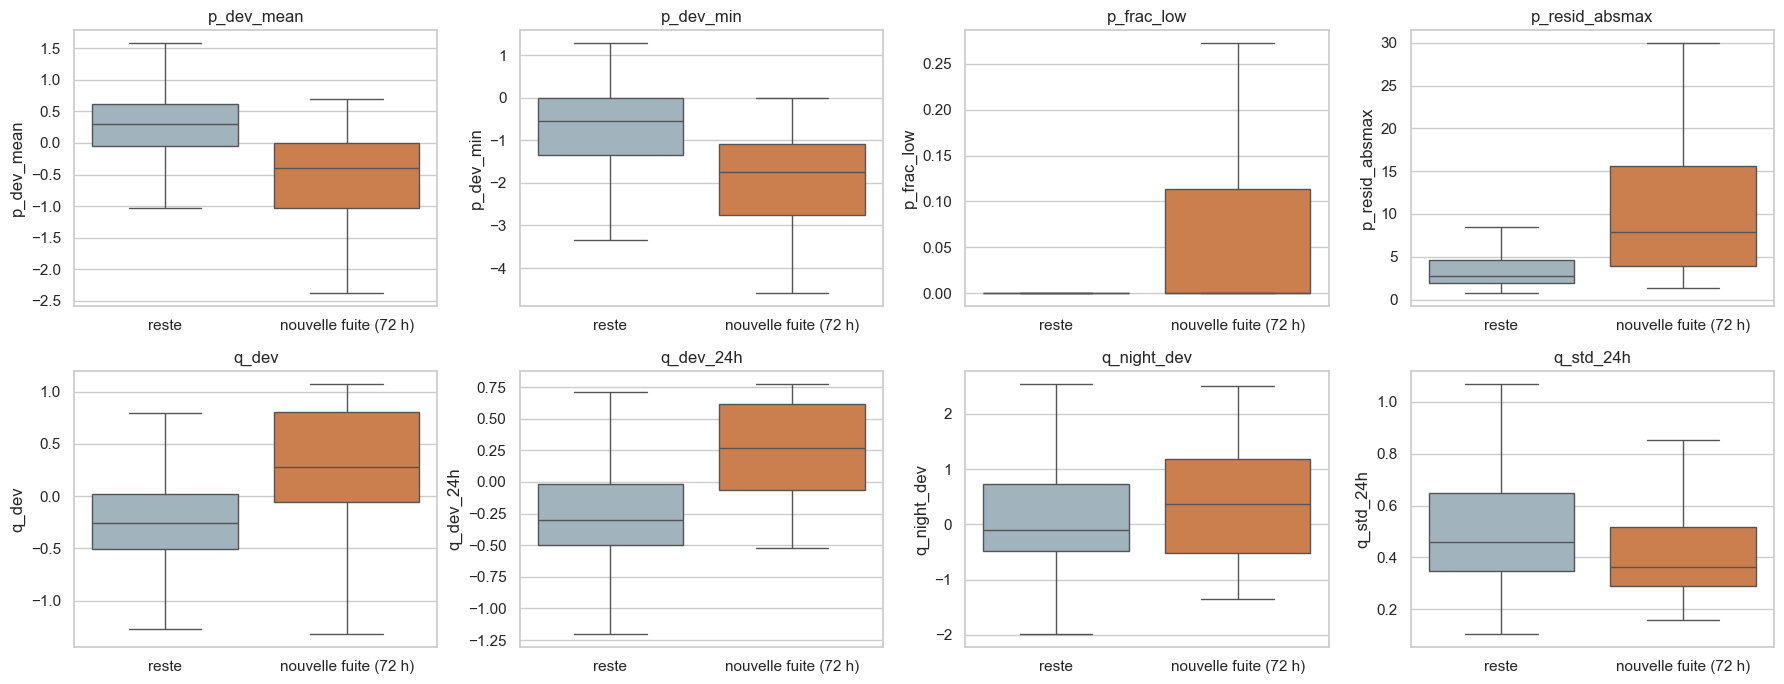

In [31]:
view = feats[valid & period.eq("val")].assign(fenetre=np.where(y_onset[valid & period.eq("val")] == 1,
                                                               "nouvelle fuite (72 h)", "reste"))
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.flat, FEATURES):
    sns.boxplot(data=view, x="fenetre", y=col, ax=ax, showfliers=False,
                hue="fenetre", palette={"nouvelle fuite (72 h)": "#e07b39", "reste": "#9db4c0"}, legend=False)
    ax.set_xlabel("")
    ax.set_title(col)
fig.tight_layout()
mlflow.log_figure(fig, "fig_features_val.png")
plt.show()

## 5. Entraînement de l'IsolationForest

Il est ajusté sur **janv.–août 2018, hors fenêtres de nouvelle fuite**. Ces données restent « majoritairement normales » au sens de l'étiquette `y_onset` : d'anciennes fuites progressives y sont actives, mais elles sont absorbées par les profils glissants. Le score d'anomalie (−`score_samples`) est lissé sur 6 h pour éviter les alarmes isolées.

In [32]:
SMOOTH_H = 6
IF_PARAMS = dict(n_estimators=300, max_samples=512, contamination="auto", random_state=SEED, n_jobs=-1)
train_rows = valid & period.eq("fit") & y_onset.eq(0)
iforest = IsolationForest(**IF_PARAMS)
iforest.fit(feats.loc[train_rows, FEATURES].to_numpy())  # numpy : pas de dépendance aux noms de colonnes
print("Lignes d'entraînement :", int(train_rows.sum()))

raw_score = pd.Series(np.nan, index=idx)
raw_score[valid] = -iforest.score_samples(feats.loc[valid, FEATURES].to_numpy())  # plus haut = plus anormal
score = raw_score.rolling(SMOOTH_H, min_periods=1).mean()
mlflow.log_params({**{f"if_{k}": v for k, v in IF_PARAMS.items()}, "smoothing_hours": SMOOTH_H,
                   "onset_hours": ONSET_H, "event_days": EVENT_DAYS, "n_features": len(FEATURES),
                   "train_rows": int(train_rows.sum()), "neighbours": K_NEIGHBOURS,
                   "resid_baseline_hours": RESID_BASELINE_H})

Lignes d'entraînement : 4777


## 6. Référence simple : CUSUM sur la chute de pression

Le **CUSUM** (somme cumulée, Page 1954) est la méthode classique de détection de rupture. Il additionne les écarts au-dessus d'une tolérance `k` et repart de 0 quand le signal redevient normal :

$$S_t = \max\big(0,\; S_{t-1} + x_t - k\big), \qquad x_t = -\,\texttt{p\_dev\_mean}_t$$

Ici, x_t est la **chute moyenne de pression** (z-score robuste, en signe positif quand la pression baisse) et k = 0,5. Ce signal n'utilise ni apprentissage ni voisins : il sert de point de comparaison. L'IsolationForest n'a d'intérêt que s'il fait mieux.

In [33]:
CUSUM_K = 0.5
x_drop = np.nan_to_num(-feats["p_dev_mean"].to_numpy(), nan=0.0)
cusum = np.zeros(len(x_drop))
s_t = 0.0
for i, x_i in enumerate(x_drop):
    s_t = max(0.0, s_t + x_i - CUSUM_K)
    cusum[i] = s_t
score_cusum = pd.Series(cusum, index=idx).where(valid)

SCORES = {"IsolationForest": score, "CUSUM pression": score_cusum}
mlflow.log_params({"cusum_k": CUSUM_K, "cusum_signal": "-p_dev_mean"})
pd.DataFrame(SCORES)[valid].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
IsolationForest,17341.0,0.439,0.065,0.347,0.386,0.424,0.483,0.677
CUSUM pression,17341.0,130.757,216.944,0.000,0.000,22.735,170.419,1173.362


## 7. Alertes par incident, évaluation par événement et seuil sous budget de fausses alertes

- **Alerte** : le score franchit le seuil vers le haut ; ensuite, pas de nouvelle alerte pendant **72 h** (même incident).
- **Fuite détectée** : une alerte démarre entre le début déclaré (arrondi à l'heure) et `min(fin, début + 72 h)`. **Délai** = heure de l'alerte − heure de début.
- **Fausse alerte** : une alerte en dehors de toutes les fenêtres de détection.
- **Seuil** : choisi sur la **validation (sept.–déc. 2018)**. On prend le seuil qui détecte le plus de fuites avec **au plus 1 fausse alerte par semaine** ; en cas d'égalité, le délai le plus court. 2019 n'intervient pas.
- **Référence aléatoire** : on tire au hasard, 2 000 fois, autant d'alertes que la méthode en a émis en 2019, et on compte les fuites ainsi « détectées ». Si la méthode ne fait pas mieux que ce hasard (p-valeur < 0,05), elle n'apporte rien.

⚠️ La validation ne contient que **2 débuts de fuite** (p158, p369). Le seuil est donc surtout déterminé par le **budget de fausses alertes**, une contrainte stable qui ne dépend que des heures normales.

In [34]:
REFRACTORY_H = 72
DETECT_H = 72
FA_BUDGET_PER_WEEK = 1.0
N_RANDOM = 2000

w_end = pd.concat([leaks["end"], leaks["start"] + pd.Timedelta(hours=DETECT_H)], axis=1).min(axis=1)
windows = pd.DataFrame({"link_id": leaks["link_id"], "type": leaks["leak_type"], "start": leaks["start"],
                        "w_start": leaks["start"].dt.floor("h"), "w_end": w_end})


def incident_alerts(sc: pd.Series, threshold: float, refractory_h: int = REFRACTORY_H) -> pd.DatetimeIndex:
    """Une alerte quand le score franchit le seuil vers le haut, puis silence pendant `refractory_h` heures."""
    above = np.nan_to_num(sc.to_numpy(), nan=-np.inf) > threshold
    rising = np.flatnonzero(above & ~np.r_[False, above[:-1]])
    kept, last = [], -10**9
    for i in rising:  # l'index est horaire et continu : une position = une heure
        if i - last >= refractory_h:
            kept.append(i)
            last = i
    return sc.index[kept]


def period_mask(name: str) -> pd.Series:
    return valid & period.eq(name)


def evaluate_alerts(alerts: pd.DatetimeIndex, name: str) -> tuple[dict, pd.DataFrame]:
    """Métriques par événement d'un jeu d'alertes sur une période ('val' ou 'test')."""
    hours = idx[period_mask(name)]
    p0, p1 = hours.min(), hours.max()
    a = alerts[(alerts >= p0) & (alerts <= p1)]
    in_window = np.zeros(len(a), dtype=bool)
    for w in windows.itertuples():
        in_window |= np.asarray((a >= w.w_start) & (a <= w.w_end))
    rows = []
    for w in windows[(windows["start"] >= p0) & (windows["start"] <= p1)].itertuples():
        hits = a[(a >= w.w_start) & (a <= w.w_end)]
        rows.append({"link_id": w.link_id, "type": w.type, "début": w.start, "détectée": len(hits) > 0,
                     "délai (h)": (hits[0] - w.w_start).total_seconds() / 3600 if len(hits) else np.nan})
    ev = pd.DataFrame(rows, columns=["link_id", "type", "début", "détectée", "délai (h)"])
    weeks = len(hours) / 168
    n_false = int((~in_window).sum())
    m = {
        "n_leaks": int(len(ev)),
        "detected": int(ev["détectée"].sum()),
        "detected_abrupt": int(ev.loc[ev["type"] == "abrupt", "détectée"].sum()),
        "n_abrupt": int((ev["type"] == "abrupt").sum()),
        "detected_incipient": int(ev.loc[ev["type"] == "incipient", "détectée"].sum()),
        "n_incipient": int((ev["type"] == "incipient").sum()),
        "median_delay_h": float(ev["délai (h)"].median()) if ev["détectée"].any() else float("nan"),
        "mean_delay_h": float(ev["délai (h)"].mean()) if ev["détectée"].any() else float("nan"),
        "n_alerts": int(len(a)),
        "false_alerts": n_false,
        "fa_per_week": n_false / weeks,
        "alert_precision": (len(a) - n_false) / len(a) if len(a) else float("nan"),
    }
    return m, ev


def calibrate(sc: pd.Series, budget: float = FA_BUDGET_PER_WEEK) -> tuple[float, pd.DataFrame]:
    """Seuil = max de fuites détectées sur la validation sous contrainte fa_per_week <= budget."""
    vals = sc[period_mask("val")].dropna()
    cands = np.unique(np.quantile(vals, np.linspace(0.50, 0.999, 150)))
    grid = pd.DataFrame([{"threshold": float(t), **evaluate_alerts(incident_alerts(sc, t), "val")[0]}
                         for t in cands])
    ok = grid[grid["fa_per_week"] <= budget]
    if ok.empty:  # budget impossible : on prend le seuil le plus silencieux
        chosen = grid.sort_values(["fa_per_week", "threshold"], ascending=[True, False]).iloc[0]
    else:
        chosen = ok.sort_values(["detected", "median_delay_h", "threshold"],
                                ascending=[False, True, True], na_position="last").iloc[0]
    return float(chosen["threshold"]), grid


def random_baseline(n_alerts: int, name: str = "test", n_sim: int = N_RANDOM) -> np.ndarray:
    """Nombre de fuites « détectées » par n_alerts alertes tirées au hasard (n_sim tirages)."""
    rng = np.random.default_rng(SEED)
    hours = idx[period_mask(name)]
    pos = hours.to_numpy().astype("datetime64[ns]").astype(np.int64)
    ev = windows[(windows["start"] >= hours.min()) & (windows["start"] <= hours.max())]
    ws = ev["w_start"].to_numpy().astype("datetime64[ns]").astype(np.int64)
    we = ev["w_end"].to_numpy().astype("datetime64[ns]").astype(np.int64)
    out = np.zeros(n_sim)
    if n_alerts == 0:
        return out
    for k in range(n_sim):
        r = np.sort(rng.choice(pos, size=min(n_alerts, len(pos)), replace=False))
        out[k] = (np.searchsorted(r, we, side="right") > np.searchsorted(r, ws, side="left")).sum()
    return out


results, events_by_method, thresholds, grids = {}, {}, {}, {}
for name, sc in SCORES.items():
    t0 = time.perf_counter()
    thr, grid = calibrate(sc)
    val_m, _ = evaluate_alerts(incident_alerts(sc, thr), "val")
    test_m, test_ev = evaluate_alerts(incident_alerts(sc, thr), "test")
    rand = random_baseline(test_m["n_alerts"])
    test_m["random_detected_mean"] = float(rand.mean())
    test_m["random_detected_p95"] = float(np.quantile(rand, 0.95))
    test_m["p_value_vs_random"] = float((rand >= test_m["detected"]).mean())
    test_m["time_above_threshold_pct"] = float((sc[period_mask("test")] > thr).mean() * 100)
    thresholds[name], grids[name], events_by_method[name] = thr, grid, test_ev
    results[name] = {"threshold": thr, "val": val_m, "test": test_m}
    print(f"{name:16s} seuil {thr:.4f} | val : {val_m['detected']}/{val_m['n_leaks']} fuites, "
          f"{val_m['fa_per_week']:.2f} FA/sem. | calibration {time.perf_counter() - t0:.1f} s")

IsolationForest  seuil 0.4277 | val : 1/2 fuites, 0.98 FA/sem. | calibration 2.1 s
CUSUM pression   seuil 22.1248 | val : 2/2 fuites, 0.00 FA/sem. | calibration 1.2 s


## 8. Résultats sur le test 2019 (19 fuites jamais vues)

In [35]:
def summary_row(name: str) -> dict:
    m = results[name]["test"]
    return {
        "méthode": name,
        "seuil": round(results[name]["threshold"], 4),
        "fuites détectées": f"{m['detected']}/{m['n_leaks']}",
        "brusques": f"{m['detected_abrupt']}/{m['n_abrupt']}",
        "progressives": f"{m['detected_incipient']}/{m['n_incipient']}",
        "délai médian (h)": round(m["median_delay_h"], 1),
        "alertes émises": m["n_alerts"],
        "fausses alertes / sem.": round(m["fa_per_week"], 2),
        "précision des alertes": round(m["alert_precision"], 2),
        "hasard : détections moyennes": round(m["random_detected_mean"], 1),
        "p-valeur vs hasard": round(m["p_value_vs_random"], 3),
        "% temps au-dessus du seuil": round(m["time_above_threshold_pct"], 1),
    }


comparison = pd.DataFrame([summary_row(n) for n in SCORES]).set_index("méthode")
display(comparison.T)


def rank_key(name: str) -> tuple:
    m = results[name]["test"]
    significant = m["p_value_vs_random"] < 0.05
    return (significant, m["detected"], -m["fa_per_week"], -np.nan_to_num(m["median_delay_h"], nan=1e9))


BEST_METHOD = max(SCORES, key=rank_key)
if_m, cu_m = results["IsolationForest"]["test"], results["CUSUM pression"]["test"]
print(f"\nMéthode la plus performante sur 2019 : {BEST_METHOD}")
if BEST_METHOD != "IsolationForest":
    print("→ L'IsolationForest NE BAT PAS la référence CUSUM : utiliser CUSUM dans l'application "
          "(ou les deux en parallèle).")
for name in SCORES:
    m = results[name]["test"]
    verdict = "mieux que le hasard" if m["p_value_vs_random"] < 0.05 else "PAS mieux que le hasard"
    print(f"  {name:16s} : {m['detected']}/{m['n_leaks']} détectées, hasard {m['random_detected_mean']:.1f} "
          f"(p = {m['p_value_vs_random']:.3f}) → {verdict}")

méthode,IsolationForest,CUSUM pression
seuil,0.4277,22.1248
fuites détectées,13/19,3/19
brusques,5/9,3/9
progressives,8/10,0/10
délai médian (h),43.0,23.0
alertes émises,74,6
fausses alertes / sem.,1.17,0.06
précision des alertes,0.18,0.5
hasard : détections moyennes,8.8,0.9
p-valeur vs hasard,0.039,0.043



Méthode la plus performante sur 2019 : IsolationForest
  IsolationForest  : 13/19 détectées, hasard 8.8 (p = 0.039) → mieux que le hasard
  CUSUM pression   : 3/19 détectées, hasard 0.9 (p = 0.043) → mieux que le hasard


In [36]:
# Sensibilité au budget de fausses alertes (seuil recalé sur la validation à chaque fois)
rows = []
for budget in [0.5, 1.0, 2.0]:
    for name, sc in SCORES.items():
        thr_b, _ = calibrate(sc, budget)
        m, _ = evaluate_alerts(incident_alerts(sc, thr_b), "test")
        rows.append({"budget FA/sem. (val)": budget, "méthode": name, "détectées": m["detected"],
                     "brusques": m["detected_abrupt"], "progressives": m["detected_incipient"],
                     "FA/sem. (test)": round(m["fa_per_week"], 2),
                     "délai médian (h)": round(m["median_delay_h"], 1)})
budget_table = pd.DataFrame(rows).set_index(["budget FA/sem. (val)", "méthode"])
budget_table

détectées  brusques  progressives  \
budget FA/sem. (val) méthode                                              
0.5                  IsolationForest         18         9             9   
                     CUSUM pression           3         3             0   
1.0                  IsolationForest         13         5             8   
                     CUSUM pression           3         3             0   
2.0                  IsolationForest         10         4             6   
                     CUSUM pression           3         3             0   

                                      FA/sem. (test)  délai médian (h)  
budget FA/sem. (val) méthode                                            
0.5                  IsolationForest            1.30              41.5  
                     CUSUM pression             0.06              23.0  
1.0                  IsolationForest            1.17              43.0  
                     CUSUM pression             0.06              23.0  
2.0                  IsolationForest            1.11              35.0  
                     CUSUM pression             0.06              23.0

Détail par fuite — IsolationForest


,link_id,type,début,détectée,délai (h)
0,p523,abrupt,2019-01-15 23:00:00,True,2.0
1,p827,abrupt,2019-01-24 18:30:00,False,NaN
2,p280,abrupt,2019-02-10 13:05:00,True,10.0
3,p653,incipient,2019-03-03 13:10:00,True,43.0
4,p710,abrupt,2019-03-24 14:15:00,True,53.0
5,p514,abrupt,2019-04-02 20:40:00,True,34.0
6,p331,abrupt,2019-04-20 10:10:00,False,NaN
7,p193,incipient,2019-05-19 10:40:00,True,60.0
8,p277,incipient,2019-05-30 21:55:00,True,56.0
9,p142,abrupt,2019-06-12 19:55:00,True,1.0


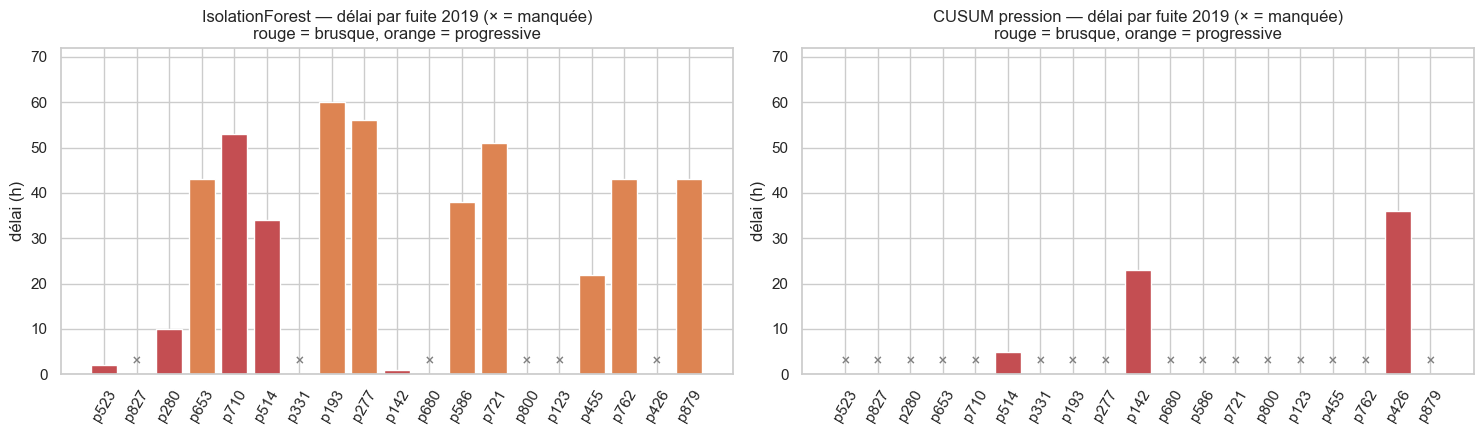

In [37]:
best_ev = events_by_method[BEST_METHOD]
print(f"Détail par fuite — {BEST_METHOD}")
display(best_ev)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, name in zip(axes, SCORES):
    ev = events_by_method[name]
    colors = np.where(ev["type"] == "abrupt", "#c44e52", "#dd8452")
    heights = ev["délai (h)"].fillna(0).to_numpy()
    ax.bar(ev["link_id"], heights, color=colors)
    for i, det in enumerate(ev["détectée"]):
        if not det:
            ax.text(i, 1, "×", ha="center", va="bottom", color="grey", fontsize=12)
    ax.set_ylim(0, DETECT_H)
    ax.set_ylabel("délai (h)")
    ax.set_title(f"{name} — délai par fuite 2019 (× = manquée)\nrouge = brusque, orange = progressive")
    ax.tick_params(axis="x", rotation=60)
fig.tight_layout()
mlflow.log_figure(fig, "fig_delais_par_fuite.png")
plt.show()

### Chronologie 2019 : scores, seuils, alertes émises et débuts de fuite

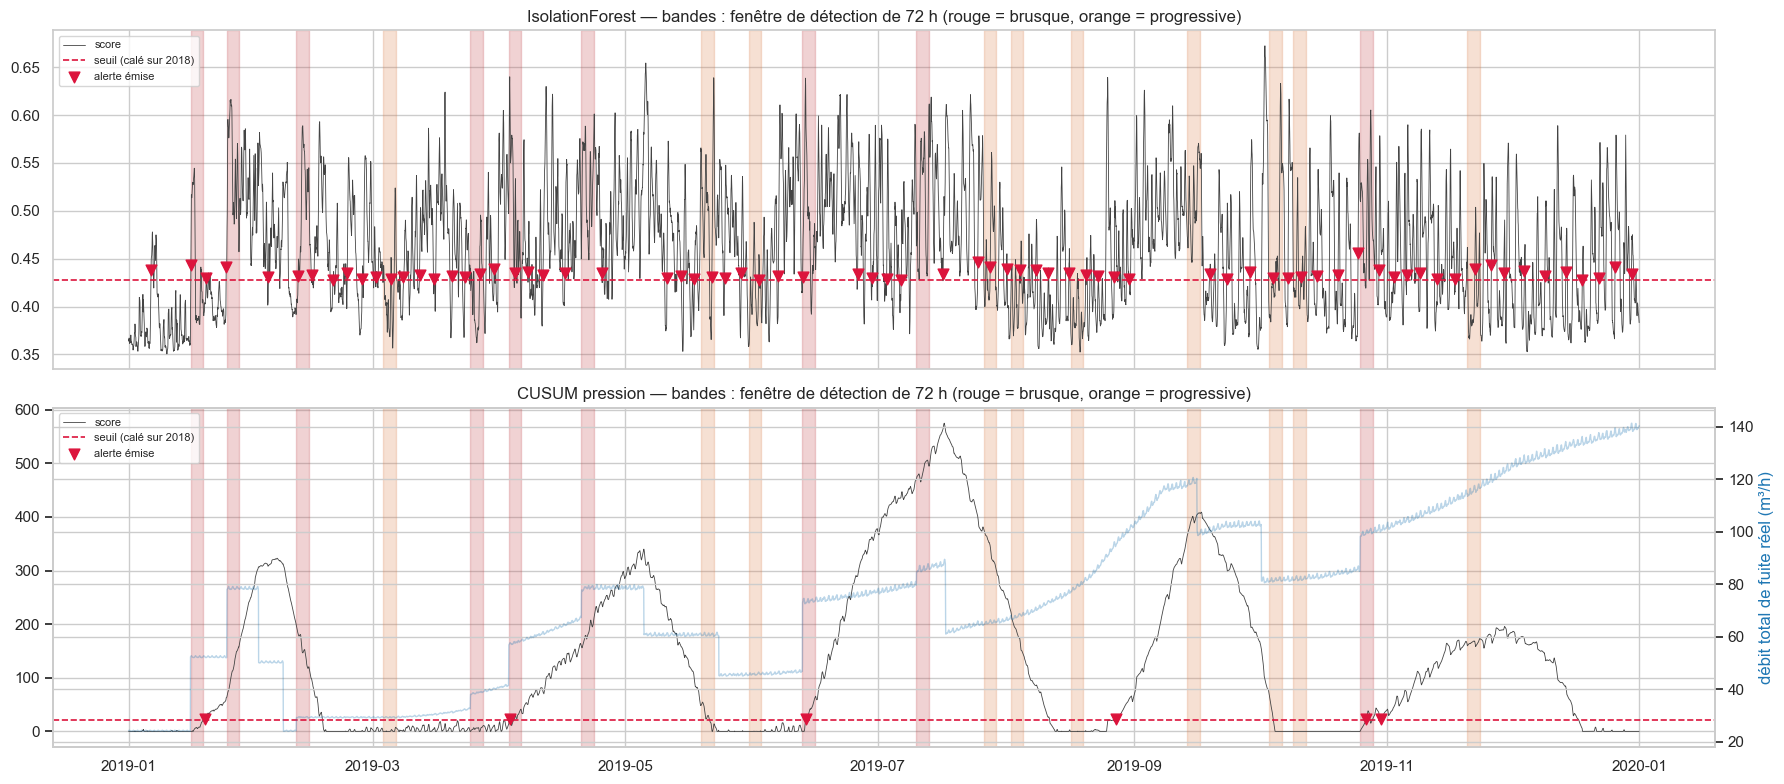

,alertes — IsolationForest,alertes — CUSUM pression,% temps > seuil — IsolationForest,% temps > seuil — CUSUM pression,nouvelles fuites
timestamp,,,,,
2019-01,4,1,34.1,40.7,2.0
2019-02,6,0,74.0,56.7,1.0
2019-03,9,0,66.3,0.0,2.0
2019-04,5,1,85.8,90.3,2.0
2019-05,6,0,80.8,65.6,2.0
2019-06,5,1,85.3,57.5,1.0
2019-07,5,0,83.6,100.0,2.0
2019-08,9,1,34.1,48.1,2.0
2019-09,3,0,75.1,100.0,1.0


In [38]:
test_mask = period_mask("test")
fig, axes = plt.subplots(2, 1, figsize=(18, 8), sharex=True)
for ax, (name, sc) in zip(axes, SCORES.items()):
    s = sc[test_mask]
    ax.plot(s.index, s, lw=0.6, color="#444", label="score")
    ax.axhline(thresholds[name], color="crimson", ls="--", lw=1.2, label="seuil (calé sur 2018)")
    al = incident_alerts(sc, thresholds[name])
    al = al[(al >= s.index.min()) & (al <= s.index.max())]
    ax.scatter(al, s.reindex(al), marker="v", s=60, color="crimson", zorder=3, label="alerte émise")
    for w in windows[windows["start"] >= TEST_START].itertuples():
        ax.axvspan(w.w_start, w.w_end, color="#c44e52" if w.type == "abrupt" else "#dd8452", alpha=0.25)
    ax.set_title(f"{name} — bandes : fenêtre de détection de 72 h (rouge = brusque, orange = progressive)")
    ax.legend(loc="upper left", fontsize=8)
ax2 = axes[1].twinx()
lf = leak_flow_h[test_mask]
ax2.plot(lf.index, lf, color="tab:blue", alpha=0.3, lw=1)
ax2.set_ylabel("débit total de fuite réel (m³/h)", color="tab:blue")
fig.tight_layout()
mlflow.log_figure(fig, "fig_chronologie_2019.png")
plt.show()

# Dérive : nombre d'alertes et temps au-dessus du seuil, par mois (2019)
monthly = pd.DataFrame({
    f"alertes — {name}": pd.Series(1, index=incident_alerts(sc, thresholds[name]))
        .reindex(idx[test_mask], fill_value=0).resample("MS").sum()
    for name, sc in SCORES.items()
})
for name, sc in SCORES.items():
    monthly[f"% temps > seuil — {name}"] = (sc[test_mask] > thresholds[name]).resample("MS").mean() * 100
monthly["nouvelles fuites"] = windows[windows["start"] >= TEST_START].set_index("start").resample("MS").size()
monthly.index = monthly.index.strftime("%Y-%m")
monthly.fillna(0).round(1)

## 9. Export des artefacts

In [39]:
joblib.dump(iforest, ARTIFACTS / "iforest.joblib")

leak_features = {
    "features": FEATURES,
    "resample": "1h (moyenne)",
    "definitions": {
        "p_dev_mean": "moyenne sur les capteurs du z-score robuste de l'écart de pression au profil hebdomadaire",
        "p_dev_min": "minimum sur les capteurs de ce même z-score (chute locale la plus forte)",
        "p_frac_low": "part des capteurs de pression avec z < -2",
        "p_resid_absmax": f"max |z| de la variation du résidu capteur-voisins (régression sur 3 voisins) vs médiane {RESID_BASELINE_H} h",
        "q_dev": "z-score robuste de l'écart du débit d'entrée au profil hebdomadaire",
        "q_dev_24h": "moyenne glissante 24 h de q_dev",
        "q_night_dev": "z-score de l'écart du débit minimal nocturne (2h-4h) à la médiane des 14 nuits précédentes",
        "q_std_24h": "écart-type glissant 24 h de q_dev",
    },
    "weekly_profile": "médiane des mêmes jour+heure sur les 4 semaines précédentes",
    "resid_baseline_hours": RESID_BASELINE_H,
    "robust_z": "x / (1.4826 × MAD), MAD calculée sur la période de référence (janv.-août 2018 hors nouvelles fuites)",
    "input_order": "tableau numpy dans l'ordre de `features` (le modèle a été ajusté sans noms de colonnes)",
    "farm_mapping": {
        "p_dev_mean": "écart moyen des pressions des tronçons S1-S5 à la pression attendue pour le plan en cours",
        "p_dev_min": "plus forte chute de pression parmi S1-S5",
        "p_frac_low": "part des tronçons en chute de pression (z < -2)",
        "p_resid_absmax": "déséquilibre du bilan de masse |S1 − (S2+S3+S4+S5)| en z-score",
        "q_dev": "résidu du débit S1 par rapport au plan d'optimisation, en z-score",
        "q_dev_24h": "moyenne glissante du résidu S1",
        "q_night_dev": "débit mesuré hors créneaux d'irrigation (doit être ≈ 0)",
        "q_std_24h": "variabilité glissante du résidu S1",
    },
    "source": "BattLeDIM 2020 (L-Town, réseau urbain) — méthode transposée au réseau d'irrigation",
}
with open(ARTIFACTS / "leak_features.json", "w", encoding="utf-8") as f:
    json.dump(leak_features, f, ensure_ascii=False, indent=2)

leak_threshold = {
    "recommended_method": BEST_METHOD,
    "alerting": {"rule": "alerte au franchissement du seuil vers le haut, puis pause (même incident)",
                 "refractory_hours": REFRACTORY_H},
    "chosen_on": f"validation sept.-déc. 2018 : max de fuites détectées avec <= {FA_BUDGET_PER_WEEK} fausse alerte/semaine",
    "iforest": {
        "threshold": thresholds["IsolationForest"],
        "score": "-IsolationForest.score_samples(X) (plus haut = plus anormal)",
        "smoothing_hours": SMOOTH_H,
        "smoothing": "moyenne glissante du score sur les 6 dernières heures",
    },
    "cusum": {
        "threshold": thresholds["CUSUM pression"],
        "signal": "x_t = -p_dev_mean (chute moyenne de pression, z-score robuste)",
        "k": CUSUM_K,
        "formula": "S_t = max(0, S_{t-1} + x_t - k)",
    },
    # compatibilité avec la version précédente (lecture directe d'un seuil)
    "threshold": thresholds["IsolationForest"],
    "smoothing_hours": SMOOTH_H,
}
with open(ARTIFACTS / "leak_threshold.json", "w", encoding="utf-8") as f:
    json.dump(leak_threshold, f, ensure_ascii=False, indent=2)


def _clean(d: dict) -> dict:
    return {k: (None if isinstance(v, float) and not np.isfinite(v) else (round(v, 4) if isinstance(v, float) else v))
            for k, v in d.items()}


leak_metrics = {
    "dataset": "BattLeDIM 2020 — L-Town (réseau urbain simulé)",
    "train": "2018 (ajustement janv.-août, seuil sept.-déc. sous budget de fausses alertes)",
    "test": "2019 (19 fuites)",
    "evaluation": (f"par incident : alerte = franchissement du seuil + pause {REFRACTORY_H} h ; fuite détectée si "
                   f"une alerte démarre dans les {DETECT_H} h suivant son début déclaré ; fausse alerte sinon"),
    "recommended_method": BEST_METHOD,
    "methods": {name: {"threshold": round(r["threshold"], 6), "val": _clean(r["val"]), "test": _clean(r["test"])}
                for name, r in results.items()},
    "budget_sensitivity": budget_table.reset_index().to_dict(orient="records"),
    # champs « à plat » de la méthode recommandée (affichage dans l'UI)
    "detected": results[BEST_METHOD]["test"]["detected"],
    "n_leaks": results[BEST_METHOD]["test"]["n_leaks"],
    "median_delay_h": _clean(results[BEST_METHOD]["test"])["median_delay_h"],
    "false_alerts_per_week": round(results[BEST_METHOD]["test"]["fa_per_week"], 3),
    "sklearn_version": sklearn.__version__,
}
with open(ARTIFACTS / "leak_metrics.json", "w", encoding="utf-8") as f:
    json.dump(leak_metrics, f, ensure_ascii=False, indent=2, default=float)

for name, r in results.items():
    key = "if" if name == "IsolationForest" else "cusum"
    mlflow.log_metrics({f"test_{key}_{k}": float(v) for k, v in r["test"].items()
                        if isinstance(v, (int, float)) and np.isfinite(v)})
    mlflow.log_metric(f"threshold_{key}", r["threshold"])
for name in ("iforest.joblib", "leak_features.json", "leak_threshold.json", "leak_metrics.json"):
    mlflow.log_artifact(str(ARTIFACTS / name))

# Contrôle : rechargement identique
reloaded = joblib.load(ARTIFACTS / "iforest.joblib")
X_check = feats.loc[valid, FEATURES].to_numpy()[:500]
assert np.allclose(reloaded.score_samples(X_check), iforest.score_samples(X_check))
print("Artefacts écrits :", ["iforest.joblib", "leak_features.json", "leak_threshold.json", "leak_metrics.json"])

Artefacts écrits : ['iforest.joblib', 'leak_features.json', 'leak_threshold.json', 'leak_metrics.json']


## Résumé des métriques

In [40]:
print(f"=== 03_leak_detection_battledim — exécuté en {time.perf_counter() - T0:.1f} s ===")
print(f"Évaluation par incident (pause {REFRACTORY_H} h, détection si alerte < {DETECT_H} h après le début), "
      f"seuils calés sur 2018 avec ≤ {FA_BUDGET_PER_WEEK} fausse alerte/semaine")
for name in SCORES:
    m = results[name]["test"]
    print(f"\n{name}  (seuil {results[name]['threshold']:.4f})")
    print(f"  fuites 2019 détectées : {m['detected']}/{m['n_leaks']}  "
          f"(brusques {m['detected_abrupt']}/{m['n_abrupt']}, progressives {m['detected_incipient']}/{m['n_incipient']})")
    print(f"  délai médian          : {m['median_delay_h']:.1f} h")
    print(f"  fausses alertes       : {m['fa_per_week']:.2f} / semaine ({m['false_alerts']} sur {m['n_alerts']} alertes)")
    print(f"  hasard (même nb d'alertes) : {m['random_detected_mean']:.1f} détections en moyenne → "
          f"p = {m['p_value_vs_random']:.3f}")
print(f"\nMéthode recommandée pour l'application : {BEST_METHOD}")
mlflow.end_run()

=== 03_leak_detection_battledim — exécuté en 17.8 s ===
Évaluation par incident (pause 72 h, détection si alerte < 72 h après le début), seuils calés sur 2018 avec ≤ 1.0 fausse alerte/semaine

IsolationForest  (seuil 0.4277)
  fuites 2019 détectées : 13/19  (brusques 5/9, progressives 8/10)
  délai médian          : 43.0 h
  fausses alertes       : 1.17 / semaine (61 sur 74 alertes)
  hasard (même nb d'alertes) : 8.8 détections en moyenne → p = 0.039

CUSUM pression  (seuil 22.1248)
  fuites 2019 détectées : 3/19  (brusques 3/9, progressives 0/10)
  délai médian          : 23.0 h
  fausses alertes       : 0.06 / semaine (3 sur 6 alertes)
  hasard (même nb d'alertes) : 0.9 détections en moyenne → p = 0.043

Méthode recommandée pour l'application : IsolationForest
